<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/14_CNN_P5_Pooling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pooling

Convolutional layers learn useful local features, but the resulting feature maps can still be very large.

Pooling layers reduce the spatial dimensions (height and width) of feature maps while preserving the most important information. This makes the network more computationally efficient and helps it become less sensitive to small shifts in the input image.

Unlike convolution, pooling does **not** use learnable filters. Instead, it summarizes values within a small window.

The two most common pooling operations are:

- **Max pooling**, which selects the largest value in each pooling window.
- **Average pooling**, which computes the average value in each pooling window.

## Maximum Pooling and Average Pooling

A pooling layer slides a fixed-size window across the input feature map, similar to a convolution. However, instead of multiplying the input by a kernel, it simply summarizes the values inside the window.

For a **2 × 2 pooling window**:

- **Max pooling** returns the largest value.
- **Average pooling** returns the average of the four values.

Pooling layers have **no learnable parameters**. Their purpose is to reduce the size of the feature map while retaining the most important information.

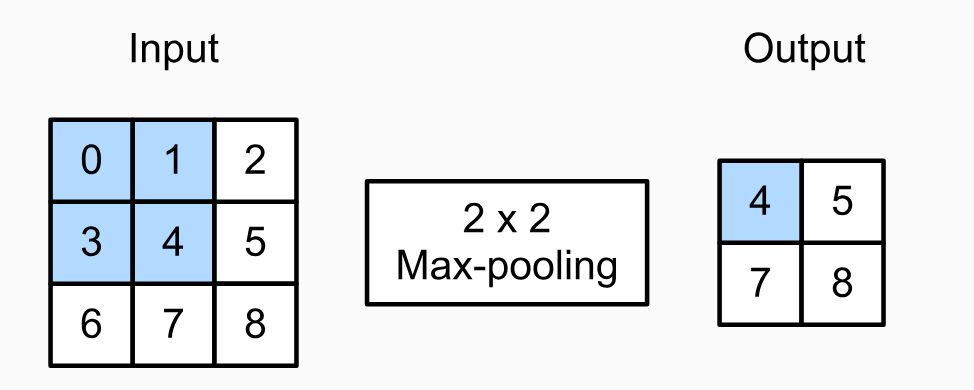

In [ ]:
import tensorflow as tf

# Apply 2D pooling to an input feature map.
#
# pool_size:
#     (height, width) of the pooling window.
#
# mode:
#     "max" for max pooling
#     "avg" for average pooling

def pool2d(X, pool_size, mode="max"):

    p_h, p_w = pool_size

    # Output feature map.
    Y = tf.Variable(
        tf.zeros((X.shape[0] - p_h + 1,
                  X.shape[1] - p_w + 1))
    )

    # Slide the pooling window across the input.
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):

            window = X[i:i+p_h, j:j+p_w]

            if mode == "max":
                Y[i, j].assign(tf.reduce_max(window))

            else:
                Y[i, j].assign(tf.reduce_mean(window))

    return Y

In [ ]:
# Example input feature map.
X = tf.constant([
    [0., 1., 2.],
    [3., 4., 5.],
    [6., 7., 8.]
])

print("Input:")
print(X.numpy())

print("\nMax pooling:")
print(pool2d(X, (2,2), "max").numpy())

print("\nAverage pooling:")
print(pool2d(X, (2,2), "avg").numpy())

Input:
[[0. 1. 2.]
 [3. 4. 5.]
 [6. 7. 8.]]

Max pooling:
[[4. 5.]
 [7. 8.]]

Average pooling:
[[2. 3.]
 [5. 6.]]


### Understanding the Results

Using a **2 × 2** pooling window:

- **Max pooling** keeps the largest value within each window.
- **Average pooling** replaces each window with its average value.

For example, the first window contains

```
0 1
3 4
```

- Max pooling returns **4**.
- Average pooling returns **2**.

Pooling reduces the height and width of the feature map while preserving its most important information.

In [ ]:
# Input feature map (same example used earlier)
X = tf.constant([
    [0., 1., 2.],
    [3., 4., 5.],
    [6., 7., 8.]
])

# TensorFlow expects input shape:
# (batch, height, width, channels)
X = tf.reshape(X, (1, 3, 3, 1))

# Create a 2 × 2 max-pooling layer
pool = tf.keras.layers.MaxPool2D(
    pool_size=2,
    strides=1
)

# Apply pooling
Y = pool(X)

print("Output:")
print(tf.squeeze(Y).numpy())

Output:
[[4. 5.]
 [7. 8.]]


In [ ]:
# Create a 2 × 2 average-pooling layer
pool = tf.keras.layers.AveragePooling2D(
    pool_size=2,
    strides=1
)

Y = pool(X)

print("Output:")
print(tf.squeeze(Y).numpy())

Output:
[[2. 3.]
 [5. 6.]]


### Why did we reshape the input?

Our feature map is originally a **3 × 3** matrix.

TensorFlow pooling layers expect a **4-dimensional tensor** with shape:

```
(batch_size, height, width, channels)
```

For this example:

- Batch size = 1 (one image)
- Height = 3
- Width = 3
- Channels = 1 (a single feature map)

Therefore, the input is reshaped from

```
(3, 3)
```

to

```
(1, 3, 3, 1)
```

After pooling, we use `tf.squeeze()` to remove the extra dimensions and display the result as a simple 2 × 2 matrix.

## Summary

Pooling layers reduce the spatial dimensions of feature maps while preserving important information.

The key ideas are:

- Pooling operates by sliding a window across the input feature map.
- **Max pooling** selects the largest value within each window.
- **Average pooling** computes the average value within each window.
- Unlike convolution, pooling layers have **no learnable parameters**.
- Pooling makes CNNs more computationally efficient and helps reduce sensitivity to small shifts in the input.